# Generative Project - Milestone #1: Image Captioning Baseline
**Student:** Shakra Fidze | Tatenda Mwashaireni



In [1]:
%pip -q install "transformers>=4.44,<5" "datasets>=3,<5" "kagglehub>=0.3,<1" "pillow>=10" "tqdm>=4.66"
# Colab already includes compatible torch, pandas, numpy, and matplotlib.

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.


## 2. Imports and reproducibility

In [2]:
import os, re, csv, json, random, hashlib, shutil
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display
from tqdm.auto import tqdm
from transformers import CLIPModel, CLIPProcessor, GPT2TokenizerFast

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
N_PAIRS = 5000
BATCH_SIZE = 32 if DEVICE == 'cuda' else 16
OUT = Path('/content/milestone1_outputs') if Path('/content').exists() else Path('milestone1_outputs')
OUT.mkdir(parents=True, exist_ok=True)
print('Device:', DEVICE, '| Outputs:', OUT)

Device: cpu | Outputs: /content/milestone1_outputs


## 3. Download Flickr8k
Uses the public Kaggle dataset `adityajn105/flickr8k` through `kagglehub`. If Kaggle requests authentication, use your Kaggle account in Colab and rerun this cell. No credentials are embedded in this notebook.

In [3]:
import kagglehub
DATA_ROOT = Path(kagglehub.dataset_download('adityajn105/flickr8k'))
print('Downloaded to:', DATA_ROOT)
files = list(DATA_ROOT.rglob('*'))
image_paths = [x for x in files if x.is_file() and x.suffix.lower() in ('.jpg','.jpeg','.png')]
caption_candidates = [x for x in files if x.is_file() and x.suffix.lower() in ('.txt','.csv') and ('caption' in x.name.lower() or 'token' in x.name.lower())]
print('Images:', len(image_paths), 'Caption files:', [str(x.relative_to(DATA_ROOT)) for x in caption_candidates])
assert image_paths, 'No images found. Inspect downloaded Kaggle folder.'
assert caption_candidates, 'No captions found. Inspect downloaded Kaggle folder.'

Using Colab cache for faster access to the 'flickr8k' dataset.
Downloaded to: /kaggle/input/flickr8k
Images: 8091 Caption files: ['captions.txt']


## 4. Parse, clean, and validate image-caption pairs

In [4]:
def parse_captions(path):
    records = []
    with open(path, 'r', encoding='utf-8-sig', errors='replace', newline='') as f:
        if path.suffix.lower() == '.csv':
            reader = csv.DictReader(f)
            names = reader.fieldnames or []
            image_col = next((c for c in names if c.lower().strip() in ('image','filename','image_name')), None)
            caption_col = next((c for c in names if c.lower().strip() in ('caption','comment','text')), None)
            if not (image_col and caption_col): return []
            for row in reader: records.append((row.get(image_col,''),row.get(caption_col,'')))
        else:
            for line in f:
                line=line.strip()
                if not line: continue
                if '\t' in line: a,b=line.split('\t',1)
                elif ',' in line: a,b=line.split(',',1)
                else: continue
                if a.lower().strip() in ('image','filename'): continue
                records.append((a,b))
    return records

def clean_caption(text):
    text = str(text).lower().strip()
    text = re.sub(r'[^a-z0-9\s\'’-]', ' ', text)
    return re.sub(r'\s+', ' ', text).strip()

image_lookup = {x.name.lower():x for x in image_paths}
parsed = [(f, parse_captions(f)) for f in caption_candidates]
source, raw = max(parsed, key=lambda x: len(x[1]))
print('Caption source:', source, 'Raw rows:', len(raw))
rows=[]
for filename, caption in raw:
    filename = Path(str(filename).split('#')[0].strip()).name.lower()
    image_path = image_lookup.get(filename)
    caption = clean_caption(caption)
    if image_path is None or not caption or len(caption.split()) < 3: continue
    rows.append({'image':image_path.name, 'image_path':str(image_path), 'caption':caption})
df = pd.DataFrame(rows).drop_duplicates(subset=['image','caption']).reset_index(drop=True)
assert len(df) >= N_PAIRS, f'Only {len(df)} valid pairs found; expected at least {N_PAIRS}.'
# Stable, reproducible sampling of 5,000 pairs, with each image/caption pair a row.
df = df.sample(n=N_PAIRS, random_state=SEED).reset_index(drop=True)
print('Clean pairs:',len(df),'Unique images:',df.image.nunique())
display(df[['image','caption']].head())
df[['image','caption']].to_csv(OUT/'cleaned_pairs.csv', index=False)

Caption source: /kaggle/input/flickr8k/captions.txt Raw rows: 40455
Clean pairs: 5000 Unique images: 3888


,image,caption
0,3335097235_538f4777c3.jpg,the white and black dog is running through a f...
1,3443853670_6c79fcfcb2.jpg,a person siting against a wall with a dog
2,3404870997_7b0cd755de.jpg,group of people watching a skateboarder do tri...
3,3424851862_0f51c42922.jpg,three people climbing rocks
4,2534502836_7a75305655.jpg,a white and tan dog runs through the tall gree...


## 5. Load pretrained CLIP and GPT-2 tokenizer

In [5]:
CLIP_ID = 'openai/clip-vit-base-patch32'
model = CLIPModel.from_pretrained(CLIP_ID).to(DEVICE).eval()
processor = CLIPProcessor.from_pretrained(CLIP_ID)
tokenizer = GPT2TokenizerFast.from_pretrained('gpt2')
tokenizer.pad_token = tokenizer.eos_token
print('CLIP:', CLIP_ID, '| GPT-2 vocab size:',tokenizer.vocab_size)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/605M [00:00<?, ?B/s]

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


model.safetensors:   0%|          | 0.00/605M [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

... (7 outputs left out)

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

CLIP: openai/clip-vit-base-patch32 | GPT-2 vocab size: 50257


## 6. Tokenize captions with GPT-2

In [6]:
tokens = tokenizer(df.caption.tolist(), padding=True, truncation=True, max_length=64, return_tensors='pt')
print('Token tensor:',tuple(tokens['input_ids'].shape))
print('First caption:',df.caption.iloc[0])
print('First token IDs:',tokens['input_ids'][0][:20].tolist())
np.save(OUT/'gpt2_input_ids.npy',tokens['input_ids'].numpy())
np.save(OUT/'gpt2_attention_mask.npy',tokens['attention_mask'].numpy())

Token tensor: (5000, 31)
First caption: the white and black dog is running through a field
First token IDs: [1169, 2330, 290, 2042, 3290, 318, 2491, 832, 257, 2214, 50256, 50256, 50256, 50256, 50256, 50256, 50256, 50256, 50256, 50256]


## 7. CLIP image embeddings (all selected pairs)

In [7]:
# Encode each unique image once; multiple caption pairs can share a photograph.
unique_images = df.drop_duplicates('image').reset_index(drop=True)
embeddings=[]; kept=[]; errors=[]
for start in tqdm(range(0,len(unique_images),BATCH_SIZE),desc='CLIP image embeddings'):
    chunk=unique_images.iloc[start:start+BATCH_SIZE]
    images=[]; indices=[]
    for idx, row in chunk.iterrows():
        try:
            with Image.open(row.image_path) as im: images.append(im.convert('RGB').copy())
            indices.append(idx)
        except Exception as e: errors.append((idx,str(e)))
    if not images: continue
    batch=processor(images=images,return_tensors='pt').to(DEVICE)
    with torch.inference_mode():
        vectors=model.get_image_features(**batch)
        if not isinstance(vectors,torch.Tensor): vectors=vectors.pooler_output
        vectors=torch.nn.functional.normalize(vectors,dim=-1)
    embeddings.append(vectors.cpu().numpy()); kept.extend(indices)
image_embeddings=np.concatenate(embeddings,axis=0)
embedded_images=unique_images.iloc[kept].reset_index(drop=True)
embedding_lookup={name:vec for name,vec in zip(embedded_images.image,image_embeddings)}
valid_df=df[df.image.isin(embedding_lookup)].reset_index(drop=True)
np.save(OUT/'clip_unique_image_embeddings.npy',image_embeddings)
embedded_images[['image']].to_csv(OUT/'embedded_image_index.csv',index=False)
valid_df[['image','caption']].to_csv(OUT/'embedded_pairs.csv',index=False)
print('Unique image embeddings:',image_embeddings.shape,'Valid caption pairs:',len(valid_df),'Unreadable images:',len(errors))
assert len(valid_df)>=5, 'Need at least five valid images.'

CLIP image embeddings:   0%|          | 0/243 [00:00<?, ?it/s]

Unique image embeddings: (3888, 512) Valid caption pairs: 5000 Unreadable images: 0


## 8. Five image-caption test runs
These are **ground-truth caption matching tests**: compute CLIP similarity between each image and its supplied caption. A larger score indicates greater embedding alignment; it is **not** an accuracy percentage or a caption-generation quality score.
These tests use **human-provided reference captions**, not model-generated captions. The CLIP encoder is an embedding baseline; a generative decoder is future work.

Test 1 | 3335097235_538f4777c3.jpg | cosine similarity: 0.2930
Reference caption: the white and black dog is running through a field


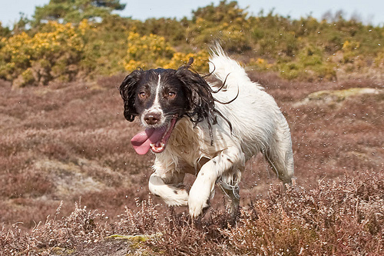

Test 2 | 3443853670_6c79fcfcb2.jpg | cosine similarity: 0.3592
Reference caption: a person siting against a wall with a dog


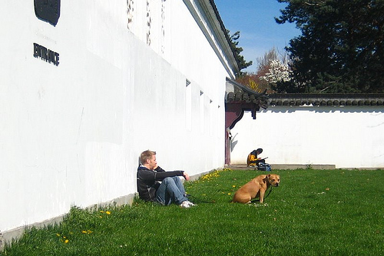

Test 3 | 3404870997_7b0cd755de.jpg | cosine similarity: 0.3156
Reference caption: group of people watching a skateboarder do tricks at a skate park


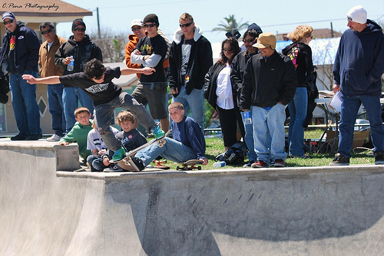

Test 4 | 3424851862_0f51c42922.jpg | cosine similarity: 0.2935
Reference caption: three people climbing rocks


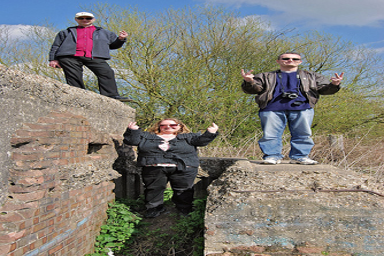

Test 5 | 2534502836_7a75305655.jpg | cosine similarity: 0.3523
Reference caption: a white and tan dog runs through the tall green grass


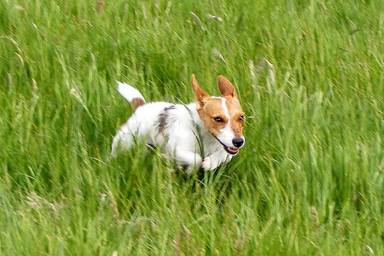

,test,image,reference_caption,clip_cosine_similarity
0,1,3335097235_538f4777c3.jpg,the white and black dog is running through a f...,0.2930
1,2,3443853670_6c79fcfcb2.jpg,a person siting against a wall with a dog,0.3592
2,3,3404870997_7b0cd755de.jpg,group of people watching a skateboarder do tri...,0.3156
3,4,3424851862_0f51c42922.jpg,three people climbing rocks,0.2935
4,5,2534502836_7a75305655.jpg,a white and tan dog runs through the tall gree...,0.3523


Mean CLIP cosine similarity: 0.3227


In [8]:
# Select five distinct images to avoid showing the same photo repeatedly.
five = valid_df.drop_duplicates('image').head(5).copy().reset_index(drop=True)
assert len(five)==5, 'Expected five distinct test images.'
results=[]
for i,row in five.iterrows():
    with Image.open(row.image_path) as im: picture=im.convert('RGB').copy()
    inputs=processor(text=[row.caption],images=[picture],return_tensors='pt',padding=True,truncation=True).to(DEVICE)
    with torch.inference_mode():
        outputs=model(**inputs)
        image_vec=torch.nn.functional.normalize(outputs.image_embeds,dim=-1)
        text_vec=torch.nn.functional.normalize(outputs.text_embeds,dim=-1)
        score=(image_vec*text_vec).sum(dim=-1).item()
    results.append({'test':i+1,'image':row.image,'reference_caption':row.caption,'clip_cosine_similarity':round(score,4)})
    print(f'Test {i+1} | {row.image} | cosine similarity: {score:.4f}')
    print('Reference caption:',row.caption)
    display(picture.resize((384,256)))
result_df=pd.DataFrame(results)
display(result_df)
result_df.to_csv(OUT/'five_test_runs.csv',index=False)
print('Mean CLIP cosine similarity:',round(result_df.clip_cosine_similarity.mean(),4))

## 9. Export evidence for proposal / submission

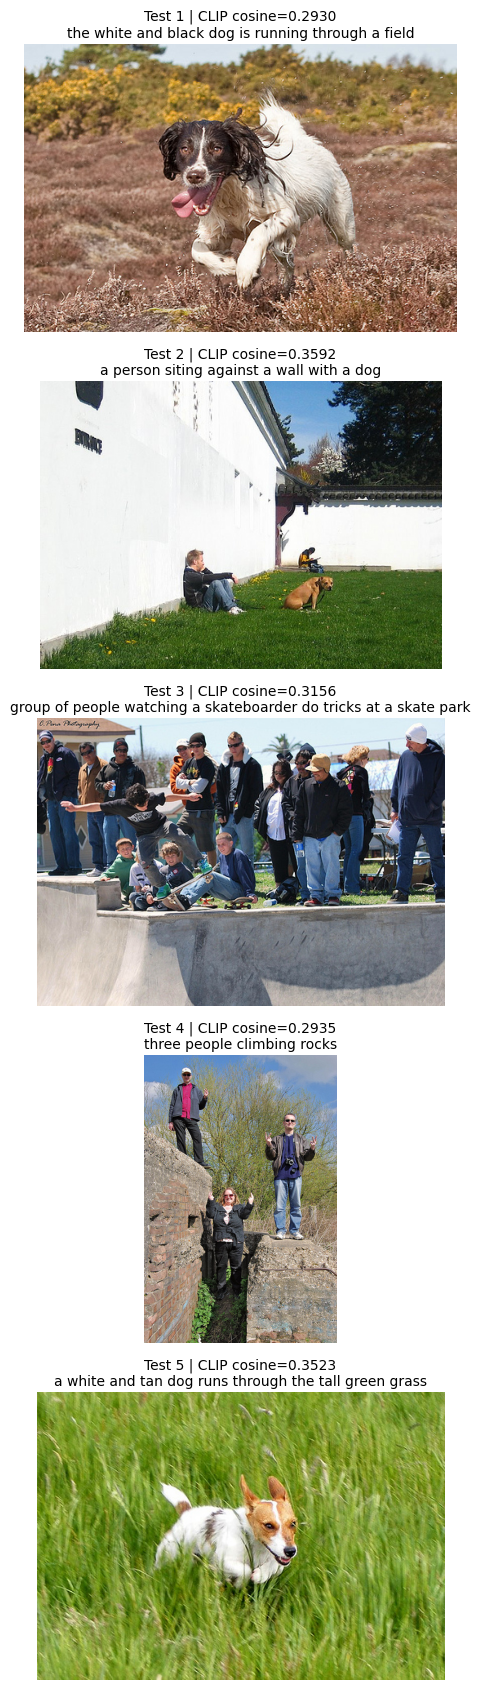

Output files:
- clip_unique_image_embeddings.npy
- gpt2_input_ids.npy
- five_test_runs.csv
- gpt2_attention_mask.npy
- run_metadata.json
- five_test_runs.png
- embedded_pairs.csv
- cleaned_pairs.csv
- embedded_image_index.csv


In [9]:
fig,axes=plt.subplots(5,1,figsize=(10,17))
for ax,(_,row),res in zip(axes,five.iterrows(),results):
    with Image.open(row.image_path) as im: ax.imshow(im.convert('RGB'))
    ax.set_title(f"Test {res['test']} | CLIP cosine={res['clip_cosine_similarity']:.4f}\n{res['reference_caption']}",fontsize=10,wrap=True)
    ax.axis('off')
plt.tight_layout()
fig.savefig(OUT/'five_test_runs.png',dpi=140,bbox_inches='tight')
plt.show()
metadata={'student':'Shakra Fidze','dataset':'Flickr8k','seed':SEED,'requested_pairs':N_PAIRS,'processed_pairs':len(valid_df),'unique_images':int(valid_df.image.nunique()),'device':DEVICE,'clip_model':CLIP_ID,'tokenizer':'gpt2','mean_similarity':float(result_df.clip_cosine_similarity.mean()),'note':'Scores compare ground-truth captions with images; no caption generator trained.'}
(OUT/'run_metadata.json').write_text(json.dumps(metadata,indent=2))
print('Output files:',*[x.name for x in OUT.iterdir()],sep='\n- ')

## 9a. Verify submission artifacts
Run this check after the five tests; it will fail if any required evidence is missing.

In [10]:
# Submission evidence checks: these must all pass after a full Colab run.
required = ['cleaned_pairs.csv','gpt2_input_ids.npy','gpt2_attention_mask.npy',
            'clip_unique_image_embeddings.npy','embedded_pairs.csv',
            'five_test_runs.csv','five_test_runs.png','run_metadata.json']
missing = [name for name in required if not (OUT/name).is_file()]
assert not missing, f'Missing output files: {missing}'
assert len(result_df)==5 and result_df.image.nunique()==5
assert len(df)==5000 and len(valid_df)>=5
assert len(image_embeddings)==embedded_images.image.nunique()
print('PASS: 5,000 pairs, unique-image embeddings, five tests and export files verified.')

PASS: 5,000 pairs, unique-image embeddings, five tests and export files verified.


## 10. Download results from Colab
The ZIP contains CSV files, embeddings, token IDs, a five-test figure, and run metadata. Submit the proposal PDF and optionally include the notebook/results as supporting evidence if your instructor permits.

In [11]:
zip_path=shutil.make_archive('/content/milestone1_results' if Path('/content').exists() else 'milestone1_results','zip',OUT)
print('Created:',zip_path)
if Path('/content').exists():
    from google.colab import files
    files.download(zip_path)

Created: /content/milestone1_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>